# Détection de défauts sur signaux vibratoires : Traitement du signal, Machine Learning et Deep Learning

**Auteur :** Maher Ben Aicha — ENIT

**Objectif :** à partir de signaux de vibration d'un moteur (dataset CWRU), détecter si un roulement est **sain** ou **défectueux**, et reconnaître le **type de défaut**.

**Pourquoi ce projet ?** La méthode est la même que pour la détection d'arcs électriques dans un courant de ligne : on a une **série temporelle échantillonnée** qu'on veut classer (défaut / pas défaut).

### Plan du notebook
1. Installation et imports
2. Téléchargement des données
3. Visualisation des signaux bruts
4. Construction du dataset (segmentation, train/test **sans fuite de données**)
5. Analyse du signal : FFT, spectrogramme, ondelettes
6. Extraction de descripteurs (temporels, fréquentiels, ondelettes)
7. Machine Learning classique : Random Forest et SVM
8. Deep Learning : 1D-CNN sur signal brut
9. Deep Learning : modèle hybride CNN-LSTM
10. Détection d'anomalies par autoencodeur (non supervisé)
11. Robustesse au bruit (SNR)
12. Synthèse des résultats et conclusion

> **Dans Colab :** `Exécution > Tout exécuter` (ou Shift+Entrée cellule par cellule). Pense à activer le GPU : `Exécution > Modifier le type d'exécution > GPU` (facultatif, ça marche aussi sur CPU).

## 1. Installation et imports

- `numpy` : calcul sur des tableaux de nombres (nos signaux).
- `scipy` : lecture des fichiers `.mat` + outils de traitement du signal (FFT, spectrogramme).
- `pywt` (PyWavelets) : transformée en ondelettes.
- `scikit-learn` : Machine Learning classique (Random Forest, SVM, métriques).
- `tensorflow / keras` : Deep Learning (CNN, LSTM, autoencodeur).

On fixe une **graine aléatoire** (`SEED`) pour que les résultats soient reproductibles : si tu relances, tu obtiens les mêmes chiffres.

In [21]:
!pip install -q PyWavelets

import os, random, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io
from scipy import signal as sps
from scipy.stats import kurtosis, skew
import pywt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, accuracy_score, roc_auc_score, roc_curve)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def save(nom):
    # Sauvegarde la figure courante dans figures/ (pour le README GitHub)
    plt.savefig(f"figures/{nom}.png", dpi=150, bbox_inches="tight")

RESULTATS = {}   # on y stocke les scores de chaque modèle pour la comparaison finale
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## 2. Téléchargement des données (CWRU Bearing Dataset)

Le **Case Western Reserve University Bearing Dataset** est un jeu de données de référence en diagnostic de défauts. Un accéléromètre mesure les vibrations d'un moteur dont on a volontairement endommagé un roulement.

On utilise 4 enregistrements (moteur à ~1797 tr/min, défaut de 0,007 pouce, capteur côté moteur = *Drive End*) :

| Fichier | Classe | Signification |
|---|---|---|
| 97.mat | Normal | roulement sain |
| 105.mat | Inner | défaut sur la bague intérieure |
| 118.mat | Ball | défaut sur une bille |
| 130.mat | Outer | défaut sur la bague extérieure |

**Fréquence d'échantillonnage `FS` = 12 000 Hz** : le capteur donne 12 000 valeurs par seconde.

> Si le téléchargement automatique échoue : télécharge les 4 fichiers depuis le site *CWRU Bearing Data Center* et glisse-les dans le dossier `data/` de Colab (icône dossier à gauche).

In [22]:
FICHIERS = {97: "Normal", 105: "Inner", 118: "Ball", 130: "Outer"}
CLASSES = list(FICHIERS.values())
FS = 12000          # Hz, fréquence d'échantillonnage des signaux de défaut
FS_NORMAL = 12000   # Vérifie sur le site CWRU (page "Normal Baseline Data"). Si c'est 48000, mets 48000 ici :
                    # le code ré-échantillonnera automatiquement le signal normal à 12 kHz.

for num in FICHIERS:
    chemin = f"data/{num}.mat"
    if not os.path.exists(chemin):
        try:
            urllib.request.urlretrieve(f"https://engineering.case.edu/sites/default/files/{num}.mat", chemin)
            print("Téléchargé :", chemin)
        except Exception as e:
            print("ÉCHEC pour", num, "->", e, "\n   => télécharge ce fichier à la main et mets-le dans data/")
    else:
        print("Déjà présent :", chemin)

Déjà présent : data/97.mat
Déjà présent : data/105.mat
Déjà présent : data/118.mat
Déjà présent : data/130.mat


In [23]:
signaux = {}
for num, nom in FICHIERS.items():
    mat = scipy.io.loadmat(f"data/{num}.mat")
    cle = [k for k in mat if k.endswith("DE_time")][0]     # accéléromètre Drive End
    x = mat[cle].flatten().astype(np.float32)
    if nom == "Normal" and FS_NORMAL != FS:
        x = sps.resample_poly(x, FS, FS_NORMAL).astype(np.float32)   # ramène à 12 kHz
    signaux[nom] = x
    print(f"{nom:7s} : {len(x):7d} points  = {len(x)/FS:5.1f} s   (clé '{cle}')")

Normal  :  243938 points  =  20.3 s   (clé 'X097_DE_time')
Inner   :  121265 points  =  10.1 s   (clé 'X105_DE_time')
Ball    :  122571 points  =  10.2 s   (clé 'X118_DE_time')
Outer   :  121991 points  =  10.2 s   (clé 'X130_DE_time')


## 3. Visualisation des signaux bruts

On trace 0,1 s de chaque signal (1200 points).

**À observer :**
- *Normal* : vibration régulière, faible amplitude.
- *Défauts* : **chocs périodiques**. À chaque fois qu'une bille passe sur le défaut, il y a un impact. Leur rythme dépend du type de défaut : c'est pour ça qu'on peut les distinguer.

C'est exactement l'intuition pour les arcs électriques : un arc crée des **perturbations brèves et irrégulières** dans le courant.

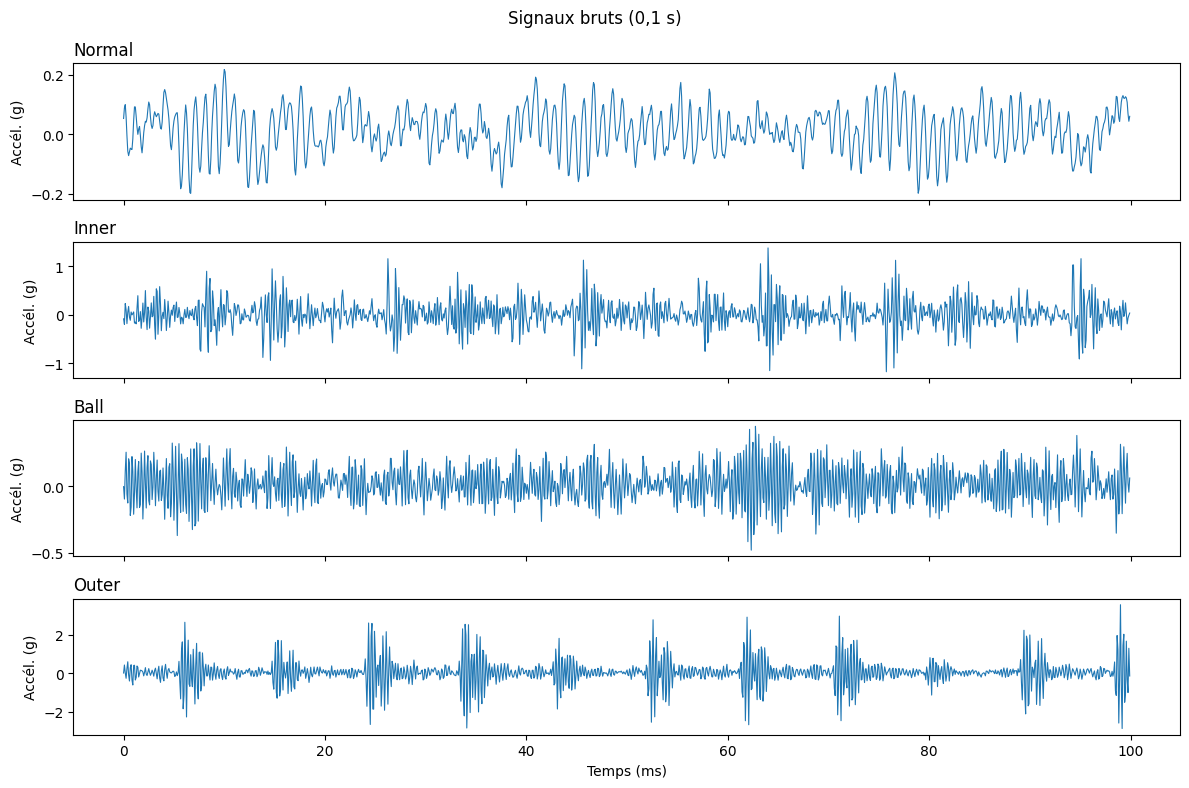

In [24]:
N = 1200
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, (nom, x) in zip(axes, signaux.items()):
    t = np.arange(N) / FS * 1000
    ax.plot(t, x[:N], lw=0.8)
    ax.set_title(nom, loc="left"); ax.set_ylabel("Accél. (g)")
axes[-1].set_xlabel("Temps (ms)")
plt.suptitle("Signaux bruts (0,1 s)"); plt.tight_layout(); save("01_signaux_bruts"); plt.show()

## 4. Construction du dataset

### 4.1 Pourquoi découper en segments ?
Un modèle a besoin de **beaucoup d'exemples**. Or on n'a que 4 longs signaux. On les découpe donc en **fenêtres** de `L = 1024` points (≈ 85 ms). Chaque fenêtre = 1 exemple, avec l'étiquette de son fichier.

### 4.2 Le piège : la fuite de données (*data leakage*)
Si on découpe avec **chevauchement** puis qu'on mélange au hasard avant de séparer train/test, deux fenêtres presque identiques se retrouvent l'une dans le train, l'autre dans le test. Le modèle "triche" et on obtient 100 % de façon artificielle.

**Notre solution :** on coupe d'abord chaque signal **dans le temps** : les 70 % premiers → entraînement, les 30 % derniers → test. **Ensuite** seulement on découpe en fenêtres.
- Train : fenêtres avec chevauchement de 50 % (pas = 512) → plus d'exemples (*data augmentation* simple).
- Test : fenêtres sans chevauchement → exemples indépendants.
- Enfin on **mélange** le train (le mélange se fait *après* la séparation, donc sans fuite).

### 4.3 Déséquilibre des classes
Le signal Normal est plus long → plus de fenêtres. C'est un cas de **données déséquilibrées** (*unbalanced data*, cité dans l'offre). On le gère avec des **poids de classe** et on évalue avec le **F1 macro** plutôt que l'accuracy seule.

In [25]:
L = 1024          # longueur d'une fenêtre
PAS_TRAIN = 512   # 50 % de chevauchement
PAS_TEST = 1024   # pas de chevauchement

def fenetrer(x, L, pas):
    n = (len(x) - L) // pas + 1
    return np.stack([x[i*pas : i*pas + L] for i in range(n)])

Xtr_list, ytr_list, Xte_list, yte_list = [], [], [], []
for label, nom in enumerate(CLASSES):
    x = signaux[nom]
    coupe = int(0.7 * len(x))
    seg_tr = fenetrer(x[:coupe], L, PAS_TRAIN)
    seg_te = fenetrer(x[coupe:], L, PAS_TEST)
    Xtr_list.append(seg_tr); ytr_list.append(np.full(len(seg_tr), label))
    Xte_list.append(seg_te); yte_list.append(np.full(len(seg_te), label))

X_train_raw = np.concatenate(Xtr_list); y_train = np.concatenate(ytr_list)
X_test_raw  = np.concatenate(Xte_list); y_test  = np.concatenate(yte_list)

# Mélange du train : sans ça, les exemples sont rangés par classe et Keras (validation_split
# prend les DERNIERS 15 %) aurait une validation contenant une seule classe !
perm = np.random.permutation(len(y_train))
X_train_raw, y_train = X_train_raw[perm], y_train[perm]

print("Train :", X_train_raw.shape, " Test :", X_test_raw.shape)
print(pd.DataFrame({"train": np.bincount(y_train), "test": np.bincount(y_test)}, index=CLASSES))

Train : (827, 1024)  Test : (176, 1024)
        train  test
Normal    332    71
Inner     164    35
Ball      166    35
Outer     165    35


## 5. Analyse du signal : temps, fréquence, temps-fréquence

C'est la partie **traitement du signal** demandée dans l'offre.

### 5.1 FFT (Transformée de Fourier)
Tout signal peut s'écrire comme une somme de sinusoïdes. La FFT donne, pour chaque fréquence *f*, **l'amplitude** de la sinusoïde correspondante.
- Axe des fréquences : de 0 à `FS/2` = 6000 Hz (**fréquence de Nyquist** : on ne peut pas voir au-delà de la moitié de la fréquence d'échantillonnage — théorème de Shannon).
- Résolution fréquentielle : `FS / L` = 12000/1024 ≈ 11,7 Hz.
- On multiplie par une **fenêtre de Hann** avant la FFT pour réduire les « fuites spectrales » (effets de bord dus au découpage).

**À observer :** les défauts font apparaître de l'énergie dans les **hautes fréquences** (les chocs excitent des résonances de la structure, souvent vers 2–4 kHz).

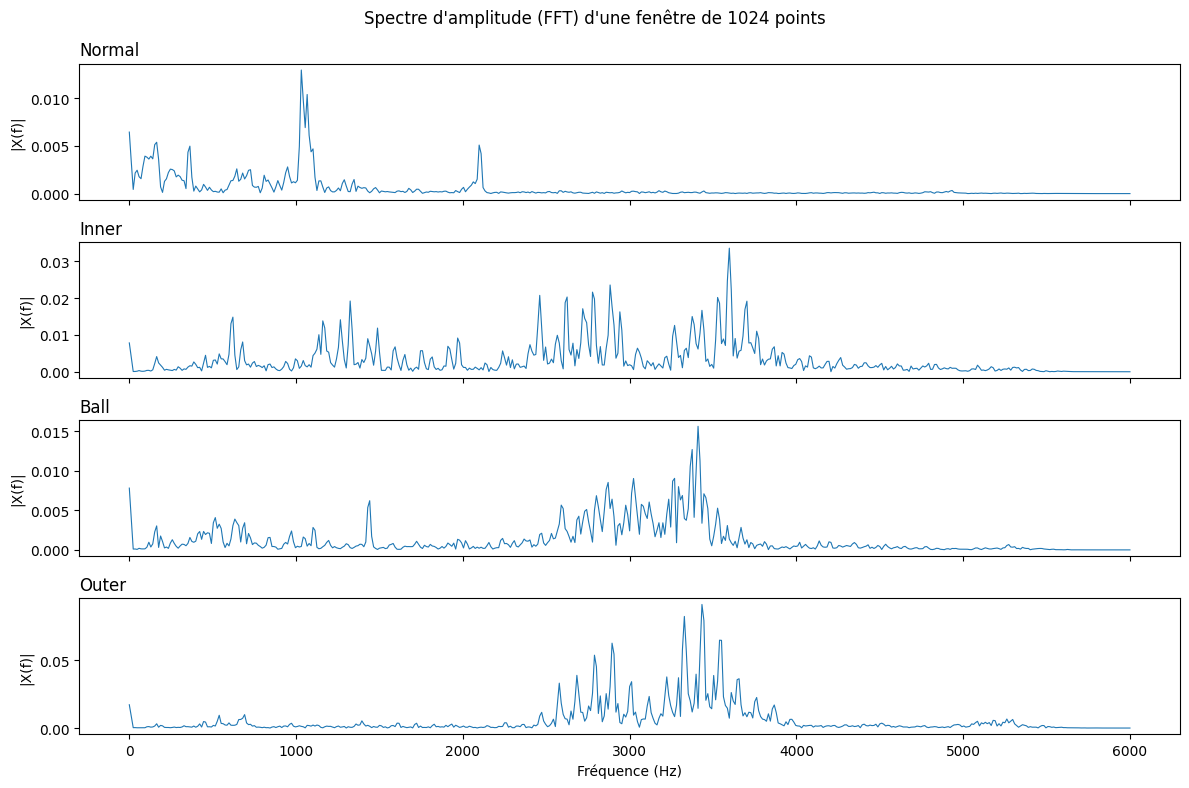

In [26]:
def spectre(seg, fs=FS):
    w = np.hanning(len(seg))
    amp = np.abs(np.fft.rfft(seg * w)) / len(seg)
    f = np.fft.rfftfreq(len(seg), 1/fs)
    return f, amp

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, (nom, x) in zip(axes, signaux.items()):
    f, a = spectre(x[:L])
    ax.plot(f, a, lw=0.8); ax.set_title(nom, loc="left"); ax.set_ylabel("|X(f)|")
axes[-1].set_xlabel("Fréquence (Hz)")
plt.suptitle("Spectre d'amplitude (FFT) d'une fenêtre de 1024 points"); plt.tight_layout(); save("02_fft"); plt.show()

### 5.2 Spectrogramme (STFT)
La FFT perd l'information de **temps** : elle dit *quelles* fréquences, pas *quand*. Le **spectrogramme** (Short-Time Fourier Transform) applique une FFT sur de petites fenêtres glissantes → une image *temps × fréquence*.

**À observer :** pour les défauts, des **bandes verticales répétées** = les chocs périodiques, bien visibles dans les hautes fréquences.

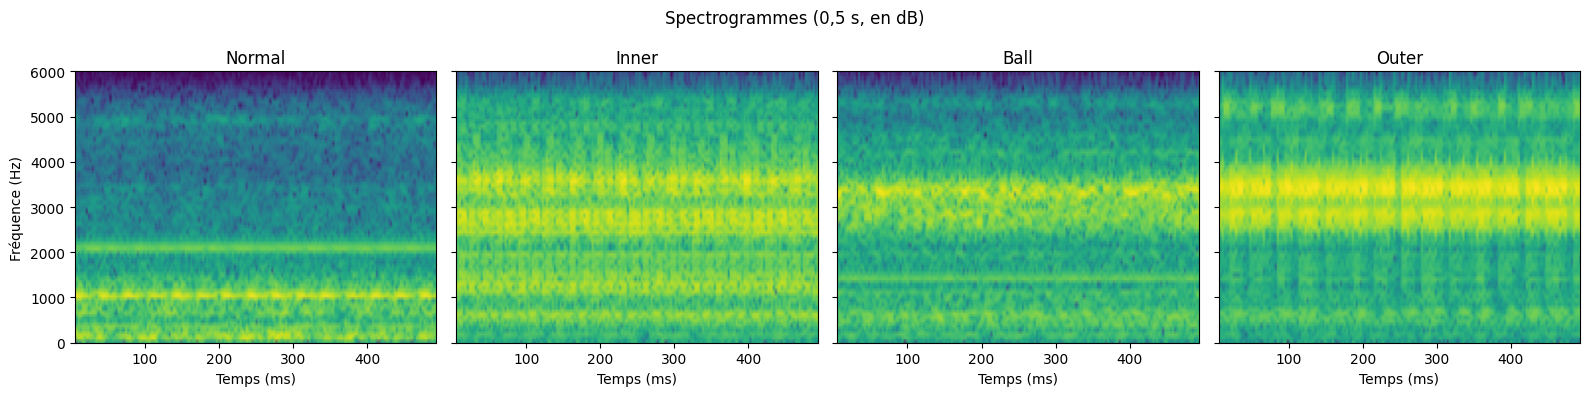

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (nom, x) in zip(axes, signaux.items()):
    f, t, S = sps.spectrogram(x[:6000], fs=FS, nperseg=128, noverlap=96)
    ax.pcolormesh(t*1000, f, 10*np.log10(S + 1e-12), shading="gouraud", cmap="viridis")
    ax.set_title(nom); ax.set_xlabel("Temps (ms)")
axes[0].set_ylabel("Fréquence (Hz)")
plt.suptitle("Spectrogrammes (0,5 s, en dB)"); plt.tight_layout(); save("03_spectrogrammes"); plt.show()

### 5.3 Ondelettes (CWT)
Le spectrogramme a un défaut : une seule taille de fenêtre → compromis fixe entre précision en temps et en fréquence.

La **transformée en ondelettes** utilise une petite onde (ici l'ondelette de **Morlet**) qu'on **étire** (basses fréquences, bonne précision fréquentielle) ou **comprime** (hautes fréquences, bonne précision temporelle). C'est idéal pour les **phénomènes transitoires brefs** : chocs mécaniques… ou **arcs électriques**.

Le résultat s'appelle un **scalogramme**. Ces images peuvent aussi servir d'entrée à un CNN 2D (piste d'amélioration).

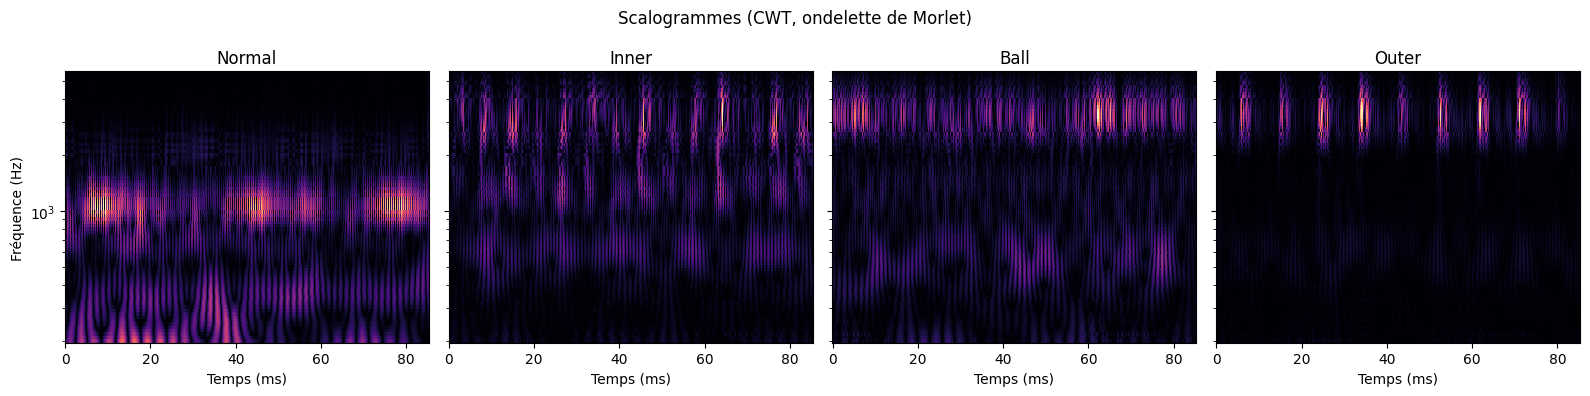

In [28]:
# On choisit les fréquences qu'on veut analyser (200 à 5500 Hz, sous Nyquist = 6000 Hz)
# et on en déduit les échelles : échelle = fréquence_centrale_ondelette × FS / fréquence
freqs_voulues = np.geomspace(5500, 200, 80)
echelles = pywt.central_frequency("morl") * FS / freqs_voulues
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (nom, x) in zip(axes, signaux.items()):
    coef, freqs = pywt.cwt(x[:L], echelles, "morl", sampling_period=1/FS)
    ax.pcolormesh(np.arange(L)/FS*1000, freqs, np.abs(coef), shading="auto", cmap="magma")
    ax.set_yscale("log")
    ax.set_title(nom); ax.set_xlabel("Temps (ms)")
axes[0].set_ylabel("Fréquence (Hz)")
plt.suptitle("Scalogrammes (CWT, ondelette de Morlet)"); plt.tight_layout(); save("04_scalogrammes"); plt.show()

## 6. Extraction de descripteurs (*feature engineering*)

Un modèle classique (Random Forest, SVM) ne sait pas lire 1024 points bruts efficacement. On résume chaque fenêtre par une vingtaine de **nombres qui ont un sens physique** :

**Temporels**
| Descripteur | Formule / sens |
|---|---|
| RMS | $\sqrt{\frac{1}{N}\sum x^2}$ : énergie moyenne |
| Pic, crête-à-crête | amplitude max |
| Facteur de crête | pic / RMS : grand si chocs |
| Kurtosis | « pointu » de la distribution ; ≈ 3 pour un signal gaussien, **>> 3 si chocs** |
| Skewness | asymétrie |
| Facteurs de forme / d'impulsion | autres indicateurs de chocs |

**Fréquentiels**
- **Centroïde spectral** : « centre de gravité » du spectre (fréquence moyenne pondérée).
- **Énergie par bande** : on divise 0–6000 Hz en 6 bandes de 1000 Hz et on mesure l'énergie de chacune.

**Ondelettes (DWT)**
- La **transformée en ondelettes discrète** (ondelette Daubechies `db4`, 4 niveaux) sépare le signal en 5 sous-bandes (approximation + 4 détails). On calcule l'**énergie relative** de chacune.

In [29]:
def descripteurs(seg):
    d = {}
    # --- temporels ---
    rms = np.sqrt(np.mean(seg**2)); pic = np.max(np.abs(seg)); moy_abs = np.mean(np.abs(seg))
    d["mean"] = np.mean(seg); d["std"] = np.std(seg); d["rms"] = rms
    d["peak"] = pic; d["p2p"] = np.ptp(seg)
    d["crest"] = pic / rms; d["kurtosis"] = kurtosis(seg, fisher=False); d["skew"] = skew(seg)
    d["shape"] = rms / moy_abs; d["impulse"] = pic / moy_abs
    # --- fréquentiels ---
    f, a = spectre(seg); p = a**2
    d["centroid"] = np.sum(f * p) / np.sum(p)
    d["f_dominante"] = f[np.argmax(a[1:]) + 1]
    for i in range(6):
        m = (f >= i*1000) & (f < (i+1)*1000)
        d[f"E_{i}-{i+1}kHz"] = np.sum(p[m]) / np.sum(p)
    # --- ondelettes (DWT) ---
    coeffs = pywt.wavedec(seg, "db4", level=4)
    energies = np.array([np.sum(c**2) for c in coeffs])
    for nom, e in zip(["A4", "D4", "D3", "D2", "D1"], energies / energies.sum()):
        d[f"W_{nom}"] = e
    return d

F_train = pd.DataFrame([descripteurs(s) for s in X_train_raw])
F_test  = pd.DataFrame([descripteurs(s) for s in X_test_raw])
print(F_train.shape, "->", F_train.shape[1], "descripteurs par fenêtre")
F_train.assign(classe=[CLASSES[i] for i in y_train]).groupby("classe").mean().round(3).T

(827, 23) -> 23 descripteurs par fenêtre


classe,Ball,Inner,Normal,Outer
mean,0.013,0.014,0.013,0.026
std,0.137,0.291,0.072,0.669
rms,0.138,0.291,0.073,0.670
peak,0.457,1.399,0.222,3.175
p2p,0.870,2.498,0.417,6.137
crest,3.316,4.804,3.019,4.743
kurtosis,2.931,5.328,2.746,7.596
skew,-0.010,0.151,-0.040,0.059
shape,1.250,1.393,1.239,1.646
impulse,4.148,6.694,3.741,7.809


**Visualisons 2 descripteurs :** si les boîtes des classes sont bien séparées, le descripteur est **discriminant**.

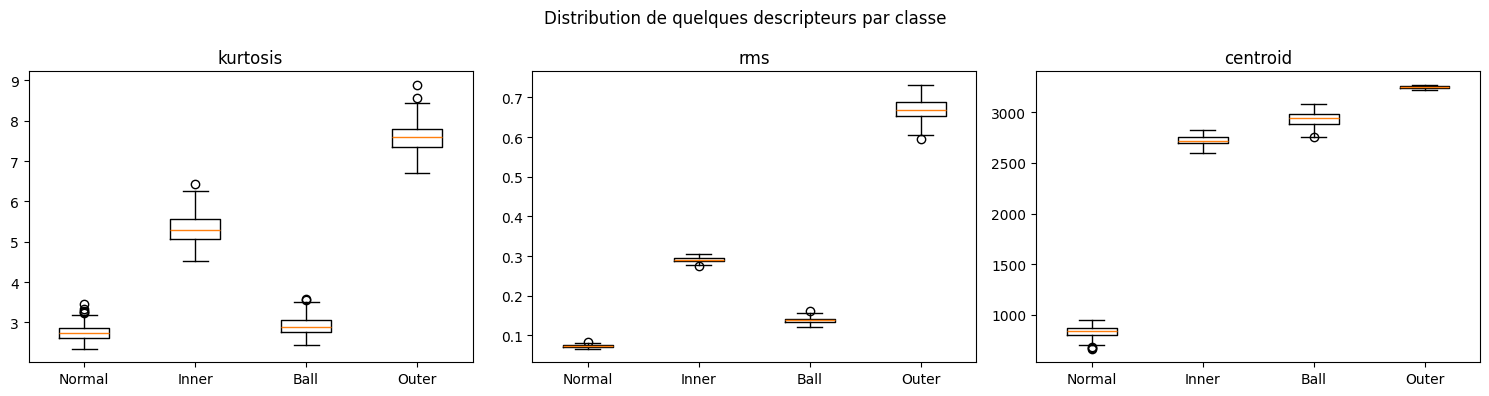

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["kurtosis", "rms", "centroid"]):
    ax.boxplot([F_train[col][y_train == i] for i in range(4)], tick_labels=CLASSES)
    ax.set_title(col)
plt.suptitle("Distribution de quelques descripteurs par classe"); plt.tight_layout(); save("05_descripteurs"); plt.show()

## 7. Machine Learning classique

### Les modèles
- **Random Forest** : un ensemble de centaines d'**arbres de décision** (« si kurtosis > 5 et rms > 0,2 alors … »). Chaque arbre vote, la majorité l'emporte. Robuste, peu de réglages, et donne l'**importance des descripteurs**.
- **SVM** (*Support Vector Machine*) : cherche la frontière qui sépare les classes avec la **marge maximale**. Le noyau RBF permet des frontières courbes. Nécessite une **normalisation** (`StandardScaler` : chaque descripteur → moyenne 0, écart-type 1).

`class_weight="balanced"` compense le déséquilibre des classes.

### Les métriques
- **Accuracy** : % de bonnes réponses. Trompeuse si classes déséquilibrées.
- **Précision** (d'une classe) : parmi ce que le modèle a prédit « Inner », combien le sont vraiment ?
- **Rappel** : parmi les vrais « Inner », combien ont été trouvés ? *Pour les arcs : un rappel faible = arcs non détectés = danger d'incendie.*
- **F1** : moyenne harmonique précision/rappel. **F1 macro** = moyenne des F1 de chaque classe (chaque classe compte pareil).
- **Matrice de confusion** : ligne = vraie classe, colonne = prédiction. Tout sur la diagonale = parfait.

===== Random Forest (descripteurs) =====  accuracy = 1.0000   F1 macro = 1.0000
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000        71
       Inner      1.000     1.000     1.000        35
        Ball      1.000     1.000     1.000        35
       Outer      1.000     1.000     1.000        35

    accuracy                          1.000       176
   macro avg      1.000     1.000     1.000       176
weighted avg      1.000     1.000     1.000       176



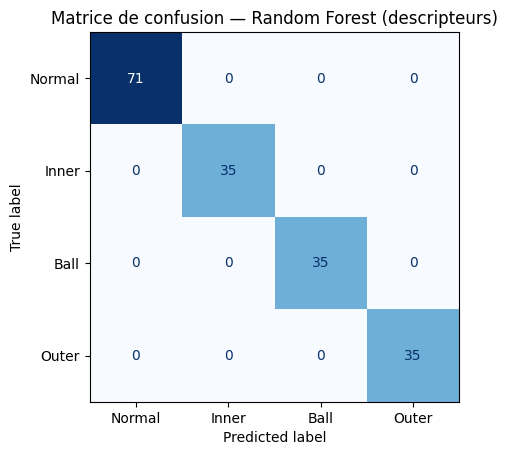

===== SVM (descripteurs) =====  accuracy = 1.0000   F1 macro = 1.0000
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000        71
       Inner      1.000     1.000     1.000        35
        Ball      1.000     1.000     1.000        35
       Outer      1.000     1.000     1.000        35

    accuracy                          1.000       176
   macro avg      1.000     1.000     1.000       176
weighted avg      1.000     1.000     1.000       176



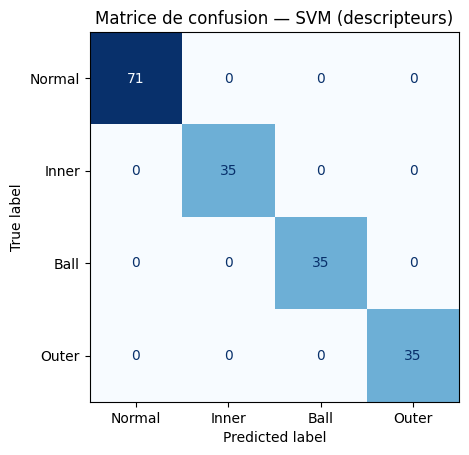

In [31]:
def evaluer(nom, y_vrai, y_pred, labels=CLASSES, fichier=None):
    acc = accuracy_score(y_vrai, y_pred); f1 = f1_score(y_vrai, y_pred, average="macro")
    RESULTATS[nom] = {"Accuracy": round(acc, 4), "F1 macro": round(f1, 4)}
    print(f"===== {nom} =====  accuracy = {acc:.4f}   F1 macro = {f1:.4f}")
    print(classification_report(y_vrai, y_pred, target_names=labels, digits=3, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y_vrai, y_pred), display_labels=labels).plot(cmap="Blues", colorbar=False)
    plt.title(f"Matrice de confusion — {nom}")
    if fichier: save(fichier)
    plt.show()

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf.fit(F_train, y_train)
evaluer("Random Forest (descripteurs)", y_test, rf.predict(F_test), fichier="06_cm_rf")

svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced"))
svm.fit(F_train, y_train)
evaluer("SVM (descripteurs)", y_test, svm.predict(F_test), fichier="07_cm_svm")

**Importance des descripteurs** (Random Forest) : quels nombres ont le plus aidé à décider ? C'est une forme d'**interprétabilité**, très appréciée en recherche. Dans le stage, cela correspond à « choix et optimisation d'un set de descripteurs performants ».

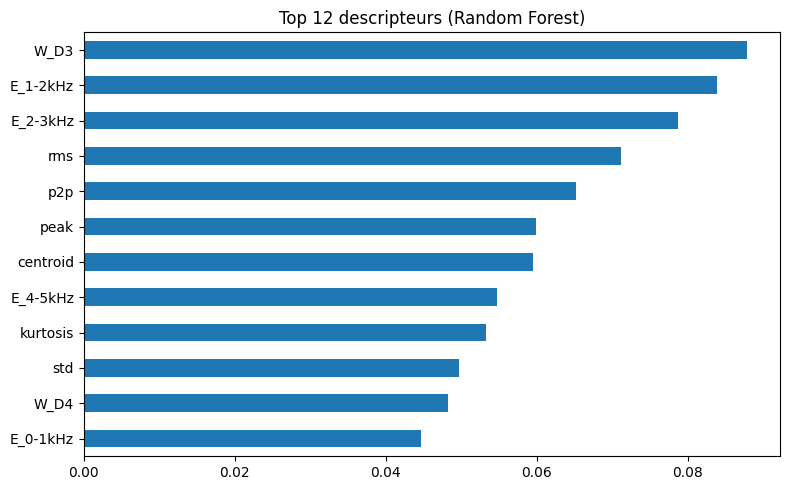

In [32]:
imp = pd.Series(rf.feature_importances_, index=F_train.columns).sort_values()
imp.tail(12).plot.barh(figsize=(8, 5)); plt.title("Top 12 descripteurs (Random Forest)")
plt.tight_layout(); save("08_importance"); plt.show()

## 8. Deep Learning : 1D-CNN sur le signal brut

### L'idée
Au lieu de calculer les descripteurs à la main, on donne **directement les 1024 points** au réseau, qui **apprend lui-même** ses propres filtres.

### Qu'est-ce qu'une convolution 1D ?
Un petit **filtre** (ex. 64 coefficients) glisse le long du signal ; à chaque position on fait un produit scalaire. Si le motif du filtre ressemble au signal local (ex. un choc), la sortie est grande. C'est exactement un **filtre FIR** en traitement du signal — sauf que les coefficients sont **appris**.

### Architecture
- 1ʳᵉ convolution **large** (noyau 64, pas 8) : capte les oscillations et réduit la longueur (idée du modèle WDCNN, classique sur ce dataset).
- Convolutions petites + `BatchNormalization` (stabilise l'apprentissage) + `MaxPooling` (réduit la taille).
- Piège rencontré : avec peu de données, la `BatchNormalization` par défaut donne 100 % en train mais de mauvais résultats en test (ses statistiques de test convergent trop lentement). On règle `momentum=0.9`.
- `GlobalAveragePooling` puis couche `Dense` `softmax` → probabilité de chacune des 4 classes.

### Pré-traitement
**Standardisation** avec la moyenne et l'écart-type calculés **sur le train uniquement** (sinon fuite de données).

### Entraînement
- **Époque** = un passage sur tout le train. **Batch** = paquet de 32 exemples traités ensemble.
- **Validation** : 15 % du train mis de côté pour surveiller le sur-apprentissage.
- **EarlyStopping** : on arrête quand la validation ne s'améliore plus, et on garde les meilleurs poids.

In [33]:
mu, sigma = X_train_raw.mean(), X_train_raw.std()
X_train = ((X_train_raw - mu) / sigma)[..., None]    # forme (n, 1024, 1) attendue par Keras
X_test  = ((X_test_raw  - mu) / sigma)[..., None]

poids = len(y_train) / (4 * np.bincount(y_train))
class_weight = {i: w for i, w in enumerate(poids)}
EPOCHS = 40

# BatchNormalization garde une moyenne "glissante" des statistiques, utilisée au moment du test.
# Par défaut (momentum=0.99) elle évolue très lentement : avec un petit dataset (peu de batchs),
# elle n'a pas le temps de converger -> 100 % en train mais mauvais en test. momentum=0.9 corrige ça.
def BN(): return layers.BatchNormalization(momentum=0.9)
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)

def modele_cnn():
    return keras.Sequential([
        layers.Input((L, 1)),
        layers.Conv1D(16, 64, strides=8, padding="same", activation="relu"),
        BN(), layers.MaxPooling1D(2),
        layers.Conv1D(32, 3, padding="same", activation="relu"),
        BN(), layers.MaxPooling1D(2),
        layers.Conv1D(64, 3, padding="same", activation="relu"),
        BN(), layers.MaxPooling1D(2),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.3),
        layers.Dense(4, activation="softmax"),
    ])

cnn = modele_cnn()
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()
hist_cnn = cnn.fit(X_train, y_train, validation_split=0.15, epochs=EPOCHS, batch_size=32,
                   class_weight=class_weight, callbacks=[stop], verbose=2)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_8 (Conv1D)               │ (None, 128, 16)        │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128, 16)        │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 64, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 64, 32)         │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 32, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 32, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,524 (37.20 KB)

 Trainable params: 9,300 (36.33 KB)

 Non-trainable params: 224 (896.00 B)

Epoch 1/40
22/22 - 13s - 588ms/step - accuracy: 0.8675 - loss: 0.4334 - val_accuracy: 0.5680 - val_loss: 0.6015
Epoch 2/40
22/22 - 0s - 8ms/step - accuracy: 1.0000 - loss: 0.0237 - val_accuracy: 1.0000 - val_loss: 0.0111
Epoch 3/40
22/22 - 0s - 8ms/step - accuracy: 1.0000 - loss: 0.0111 - val_accuracy: 1.0000 - val_loss: 0.0028
Epoch 4/40
22/22 - 0s - 8ms/step - accuracy: 1.0000 - loss: 0.0072 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 5/40
22/22 - 0s - 8ms/step - accuracy: 1.0000 - loss: 0.0063 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 6/40
22/22 - 0s - 7ms/step - accuracy: 1.0000 - loss: 0.0052 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 7/40
22/22 - 0s - 14ms/step - accuracy: 1.0000 - loss: 0.0035 - val_accuracy: 1.0000 - val_loss: 9.5151e-04
Epoch 8/40
22/22 - 0s - 11ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 1.0000 - val_loss: 7.5461e-04
Epoch 9/40
22/22 - 0s - 11ms/step - accuracy: 1.0000 - loss: 0.0027 - val_accuracy: 1.0000 - val_loss: 6.2499e-04
E

**Courbes d'apprentissage** : si la courbe *train* continue de baisser alors que *validation* remonte → **sur-apprentissage** (le modèle apprend par cœur au lieu de généraliser).

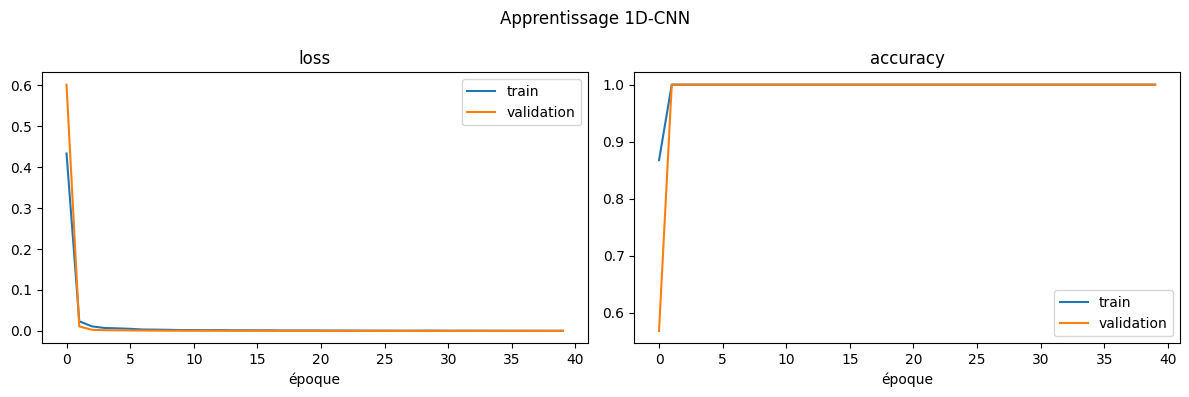

===== 1D-CNN (signal brut) =====  accuracy = 1.0000   F1 macro = 1.0000
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000        71
       Inner      1.000     1.000     1.000        35
        Ball      1.000     1.000     1.000        35
       Outer      1.000     1.000     1.000        35

    accuracy                          1.000       176
   macro avg      1.000     1.000     1.000       176
weighted avg      1.000     1.000     1.000       176



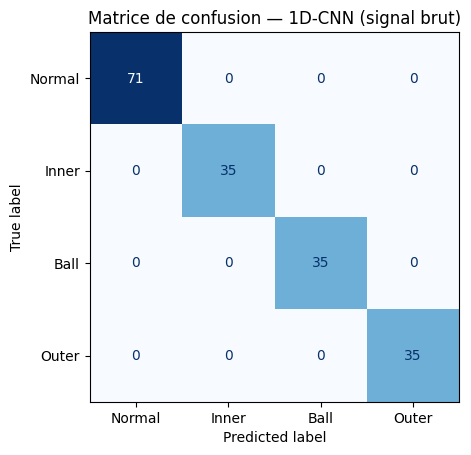

In [34]:
def courbes(hist, titre, fichier):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, m in zip(axes, ["loss", "accuracy"]):
        ax.plot(hist.history[m], label="train"); ax.plot(hist.history["val_" + m], label="validation")
        ax.set_title(m); ax.set_xlabel("époque"); ax.legend()
    plt.suptitle(titre); plt.tight_layout(); save(fichier); plt.show()

courbes(hist_cnn, "Apprentissage 1D-CNN", "09_courbes_cnn")
evaluer("1D-CNN (signal brut)", y_test, cnn.predict(X_test, verbose=0).argmax(1), fichier="10_cm_cnn")

## 9. Deep Learning : modèle hybride CNN-LSTM

### Qu'est-ce qu'un LSTM ?
Un réseau **récurrent** : il lit une séquence pas à pas et garde une **mémoire** (portes d'entrée, d'oubli, de sortie) de ce qu'il a vu. Parfait pour capter des **dépendances temporelles** (ex. la **répétition** des chocs).

### Pourquoi hybride ?
Un LSTM sur 1024 pas serait lent et difficile à entraîner. On met d'abord des **convolutions** qui extraient des motifs locaux et raccourcissent la séquence (1024 → 32 pas), puis le **LSTM** analyse l'enchaînement de ces motifs. C'est l'architecture **CNN + LSTM** mentionnée dans l'offre de stage.

Epoch 1/40
22/22 - 2s - 113ms/step - accuracy: 0.7877 - loss: 0.7878 - val_accuracy: 0.7440 - val_loss: 0.5892
Epoch 2/40
22/22 - 0s - 13ms/step - accuracy: 0.9986 - loss: 0.1287 - val_accuracy: 1.0000 - val_loss: 0.0287
Epoch 3/40
22/22 - 0s - 13ms/step - accuracy: 1.0000 - loss: 0.0244 - val_accuracy: 1.0000 - val_loss: 0.0115
Epoch 4/40
22/22 - 0s - 15ms/step - accuracy: 1.0000 - loss: 0.0131 - val_accuracy: 1.0000 - val_loss: 0.0073
Epoch 5/40
22/22 - 0s - 13ms/step - accuracy: 1.0000 - loss: 0.0097 - val_accuracy: 1.0000 - val_loss: 0.0053
Epoch 6/40
22/22 - 0s - 18ms/step - accuracy: 1.0000 - loss: 0.0071 - val_accuracy: 1.0000 - val_loss: 0.0040


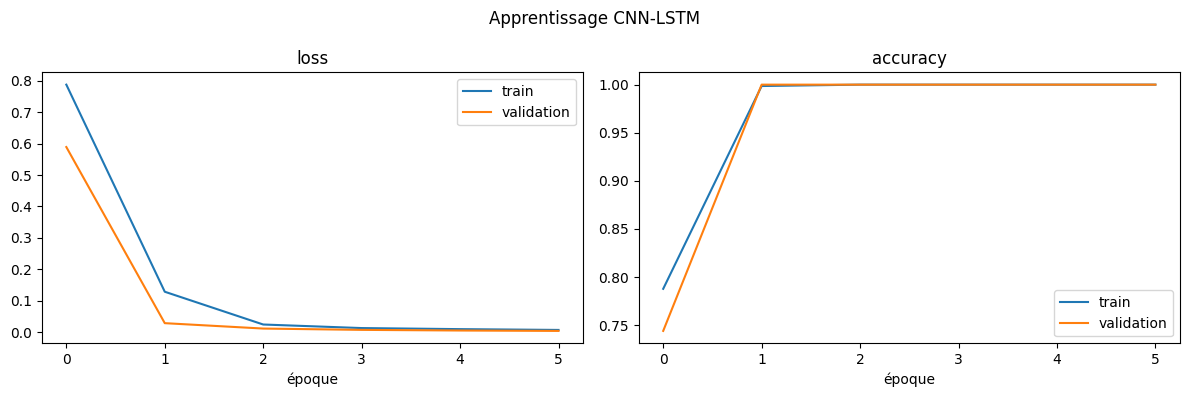

===== CNN-LSTM (signal brut) =====  accuracy = 0.8239   F1 macro = 0.8534
              precision    recall  f1-score   support

      Normal      1.000     0.563     0.721        71
       Inner      1.000     1.000     1.000        35
        Ball      0.530     1.000     0.693        35
       Outer      1.000     1.000     1.000        35

    accuracy                          0.824       176
   macro avg      0.883     0.891     0.853       176
weighted avg      0.907     0.824     0.826       176



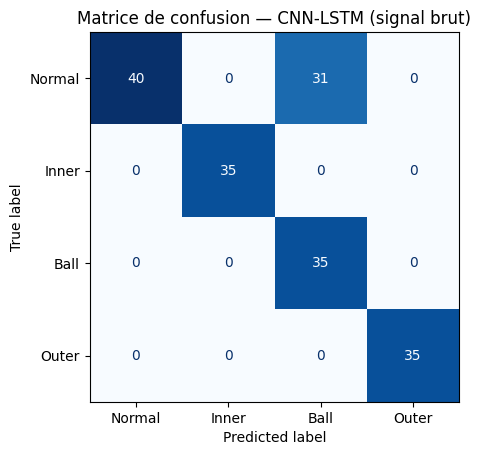

In [35]:
cnn_lstm = keras.Sequential([
    layers.Input((L, 1)),
    layers.Conv1D(16, 64, strides=8, padding="same", activation="relu"),
    BN(), layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, padding="same", activation="relu"),
    BN(), layers.MaxPooling1D(2),       # -> séquence de 32 pas × 32 canaux
    layers.LSTM(64),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax"),
])
cnn_lstm.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_lstm = cnn_lstm.fit(X_train, y_train, validation_split=0.15, epochs=EPOCHS, batch_size=32,
                         class_weight=class_weight, callbacks=[stop], verbose=2)
courbes(hist_lstm, "Apprentissage CNN-LSTM", "11_courbes_cnn_lstm")
evaluer("CNN-LSTM (signal brut)", y_test, cnn_lstm.predict(X_test, verbose=0).argmax(1), fichier="12_cm_cnn_lstm")

## 10. Détection d'anomalies par autoencodeur

### Le problème réel
Dans la réalité (et pour les arcs électriques), on a **beaucoup de données normales** et **très peu de données de défaut**. Parfois aucune pour un nouveau type de défaut !

### L'idée de l'autoencodeur
Un réseau en forme de sablier :
- **Encodeur** : compresse la fenêtre de 1024 points en un petit **code** (espace latent).
- **Décodeur** : reconstruit les 1024 points à partir du code.

On l'entraîne **uniquement sur des signaux normaux** à reproduire son entrée. Il devient expert du « normal ».
Face à un signal défectueux (jamais vu), il **reconstruit mal** → **erreur de reconstruction élevée** → **alarme**.

### Le seuil
On calcule l'erreur sur des données normales de validation et on fixe le seuil au **99ᵉ percentile** : ≈ 1 % de fausses alarmes tolérées.

**Lien avec l'offre** : les autoencodeurs (et leurs cousins les **VAE** et **GAN**) sont aussi des **modèles génératifs** qu'on peut utiliser pour **générer des données synthétiques** et augmenter une base.

On évalue ici en binaire : **Normal (0) vs Défaut (1)**, avec en plus l'**AUC ROC** (1 = séparation parfaite, 0,5 = hasard).

Epoch 1/40
9/9 - 5s - 501ms/step - loss: 0.0459 - val_loss: 0.0432
Epoch 2/40
9/9 - 0s - 15ms/step - loss: 0.0390 - val_loss: 0.0285
Epoch 3/40
9/9 - 0s - 13ms/step - loss: 0.0201 - val_loss: 0.0135
Epoch 4/40
9/9 - 0s - 14ms/step - loss: 0.0098 - val_loss: 0.0089
Epoch 5/40
9/9 - 0s - 13ms/step - loss: 0.0074 - val_loss: 0.0065
Epoch 6/40
9/9 - 0s - 13ms/step - loss: 0.0059 - val_loss: 0.0050
Epoch 7/40
9/9 - 0s - 14ms/step - loss: 0.0047 - val_loss: 0.0041
Epoch 8/40
9/9 - 0s - 14ms/step - loss: 0.0038 - val_loss: 0.0035
Epoch 9/40
9/9 - 0s - 14ms/step - loss: 0.0033 - val_loss: 0.0030
Epoch 10/40
9/9 - 0s - 18ms/step - loss: 0.0029 - val_loss: 0.0027
Epoch 11/40
9/9 - 0s - 13ms/step - loss: 0.0025 - val_loss: 0.0024
Epoch 12/40
9/9 - 0s - 14ms/step - loss: 0.0023 - val_loss: 0.0021
Epoch 13/40
9/9 - 0s - 13ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 14/40
9/9 - 0s - 14ms/step - loss: 0.0018 - val_loss: 0.0016
Epoch 15/40
9/9 - 0s - 13ms/step - loss: 0.0015 - val_loss: 0.0013
Epo

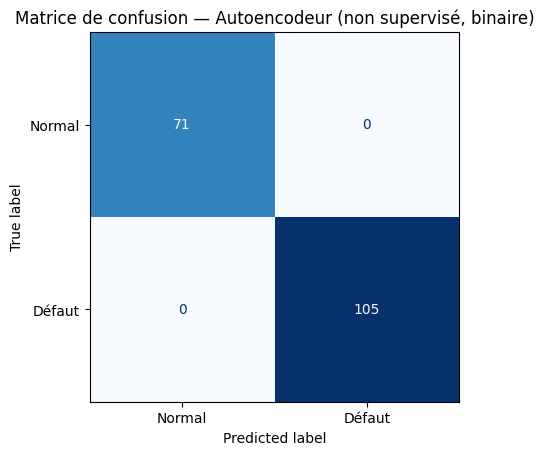

In [36]:
X_norm = X_train[y_train == 0]
n_val = int(0.2 * len(X_norm))
X_norm_tr, X_norm_val = X_norm[:-n_val], X_norm[-n_val:]   # split temporel, pas aléatoire

ae = keras.Sequential([
    layers.Input((L, 1)),
    layers.Conv1D(32, 7, strides=2, padding="same", activation="relu"),   # 512
    layers.Conv1D(16, 7, strides=2, padding="same", activation="relu"),   # 256
    layers.Conv1D(8, 7, strides=2, padding="same", activation="relu"),    # 128 × 8 = code latent
    layers.Conv1DTranspose(16, 7, strides=2, padding="same", activation="relu"),
    layers.Conv1DTranspose(32, 7, strides=2, padding="same", activation="relu"),
    layers.Conv1DTranspose(1, 7, strides=2, padding="same"),              # retour à 1024 × 1
])
ae.compile(optimizer="adam", loss="mse")
ae.fit(X_norm_tr, X_norm_tr, validation_data=(X_norm_val, X_norm_val), epochs=EPOCHS, batch_size=32,
       callbacks=[keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)], verbose=2)

def erreur(X): return np.mean((ae.predict(X, verbose=0) - X) ** 2, axis=(1, 2))

seuil = np.percentile(erreur(X_norm_val), 99)
err_test = erreur(X_test)
y_bin = (y_test != 0).astype(int)
y_pred_bin = (err_test > seuil).astype(int)
print(f"Seuil = {seuil:.4f}   AUC ROC = {roc_auc_score(y_bin, err_test):.4f}")
evaluer("Autoencodeur (non supervisé, binaire)", y_bin, y_pred_bin, labels=["Normal", "Défaut"], fichier="13_cm_ae")

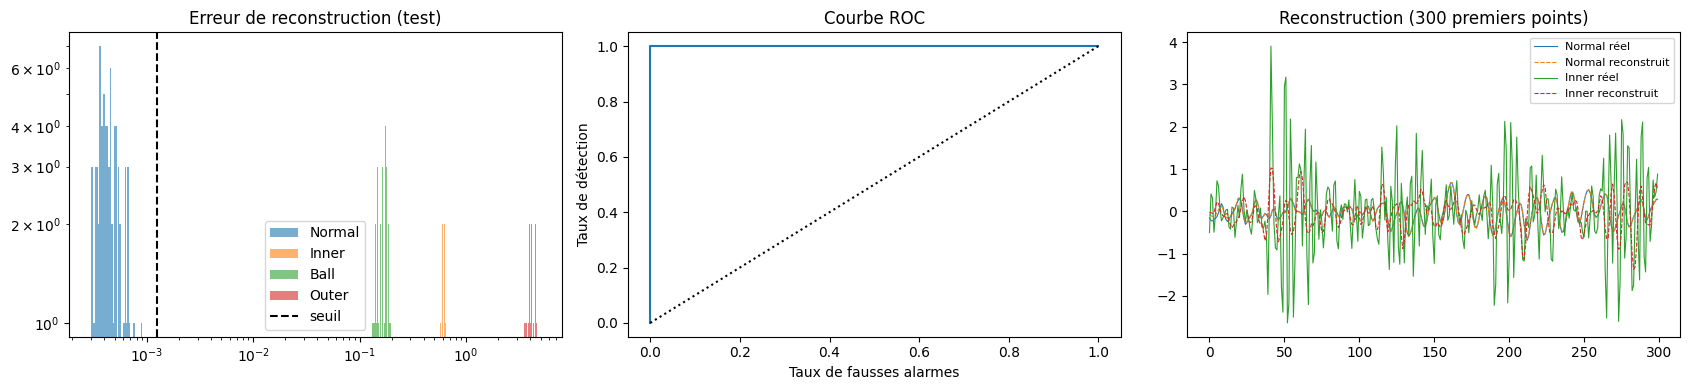

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for i, nom in enumerate(CLASSES):
    axes[0].hist(err_test[y_test == i], bins=40, alpha=0.6, label=nom, log=True)
axes[0].axvline(seuil, color="k", ls="--", label="seuil"); axes[0].set_xscale("log")
axes[0].set_title("Erreur de reconstruction (test)"); axes[0].legend()

fpr, tpr, _ = roc_curve(y_bin, err_test)
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [0, 1], "k:")
axes[1].set_title("Courbe ROC"); axes[1].set_xlabel("Taux de fausses alarmes"); axes[1].set_ylabel("Taux de détection")

i_def = np.where(y_test == 1)[0][0]; i_nor = np.where(y_test == 0)[0][0]
for idx, nom in [(i_nor, "Normal"), (i_def, "Inner")]:
    axes[2].plot(X_test[idx, :300, 0], lw=0.8, label=f"{nom} réel")
    axes[2].plot(ae.predict(X_test[idx:idx+1], verbose=0)[0, :300, 0], "--", lw=0.8, label=f"{nom} reconstruit")
axes[2].set_title("Reconstruction (300 premiers points)"); axes[2].legend(fontsize=8)
plt.tight_layout(); save("14_autoencodeur"); plt.show()

## 11. Robustesse au bruit

En conditions réelles (avion !), les capteurs sont **bruités**. Un bon chercheur ne s'arrête pas à « 99 % en labo » : il teste les **limites** du modèle (« Évaluation des limites et optimisation des performances » dans l'offre).

On ajoute un **bruit blanc gaussien** au signal de test avec un **SNR** (*Signal-to-Noise Ratio*) donné :
$$\text{SNR}_{dB} = 10 \log_{10}\frac{P_{signal}}{P_{bruit}}$$
- 20 dB : bruit 100× plus faible que le signal (peu bruité)
- 0 dB : bruit aussi fort que le signal (très bruité)

Les modèles sont entraînés sur les données **propres** et testés sur les données **bruitées**.

SNR 30 dB : Random Forest=1.000  SVM=1.000  1D-CNN=1.000  CNN-LSTM=0.849
SNR 20 dB : Random Forest=1.000  SVM=1.000  1D-CNN=1.000  CNN-LSTM=0.849
SNR 10 dB : Random Forest=1.000  SVM=0.888  1D-CNN=1.000  CNN-LSTM=0.765
SNR  5 dB : Random Forest=0.919  SVM=0.090  1D-CNN=1.000  CNN-LSTM=0.669
SNR  0 dB : Random Forest=0.613  SVM=0.083  1D-CNN=0.732  CNN-LSTM=0.627


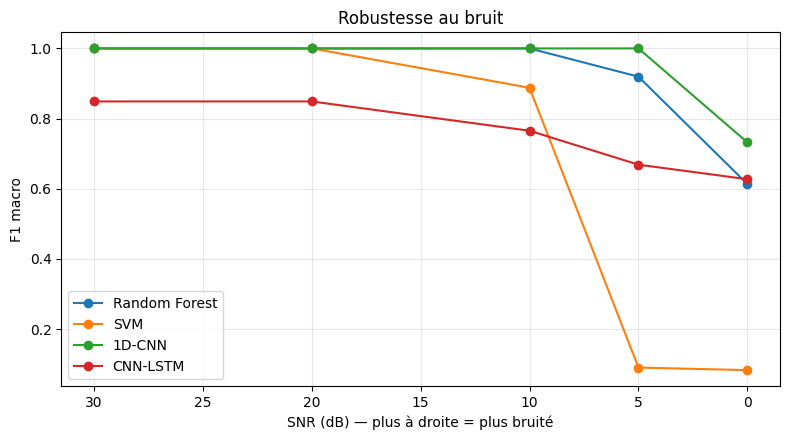

In [38]:
def ajouter_bruit(X, snr_db, rng=np.random.default_rng(SEED)):
    p_sig = np.mean(X**2, axis=1, keepdims=True)
    p_bruit = p_sig / (10 ** (snr_db / 10))
    return X + rng.normal(size=X.shape) * np.sqrt(p_bruit)

SNRs = [30, 20, 10, 5, 0]
courbes_snr = {"Random Forest": [], "SVM": [], "1D-CNN": [], "CNN-LSTM": []}
for snr in SNRs:
    Xb = ajouter_bruit(X_test_raw, snr).astype(np.float32)
    Fb = pd.DataFrame([descripteurs(s) for s in Xb])
    Xb_n = ((Xb - mu) / sigma)[..., None]
    courbes_snr["Random Forest"].append(f1_score(y_test, rf.predict(Fb), average="macro"))
    courbes_snr["SVM"].append(f1_score(y_test, svm.predict(Fb), average="macro"))
    courbes_snr["1D-CNN"].append(f1_score(y_test, cnn.predict(Xb_n, verbose=0).argmax(1), average="macro"))
    courbes_snr["CNN-LSTM"].append(f1_score(y_test, cnn_lstm.predict(Xb_n, verbose=0).argmax(1), average="macro"))
    print(f"SNR {snr:>2} dB : " + "  ".join(f"{k}={v[-1]:.3f}" for k, v in courbes_snr.items()))

plt.figure(figsize=(8, 4.5))
for k, v in courbes_snr.items(): plt.plot(SNRs, v, "o-", label=k)
plt.gca().invert_xaxis(); plt.xlabel("SNR (dB) — plus à droite = plus bruité"); plt.ylabel("F1 macro")
plt.title("Robustesse au bruit"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); save("15_robustesse_bruit"); plt.show()

## 12. Synthèse des résultats

In [39]:
res = pd.DataFrame(RESULTATS).T
res

,Accuracy,F1 macro
Random Forest (descripteurs),1.0000,1.0000
SVM (descripteurs),1.0000,1.0000
1D-CNN (signal brut),1.0000,1.0000
CNN-LSTM (signal brut),0.8239,0.8534
"Autoencodeur (non supervisé, binaire)",1.0000,1.0000


## Conclusion

### Ce que montre ce projet
- **Traitement du signal** : FFT, spectrogramme et ondelettes rendent les défauts visibles (chocs périodiques, énergie haute fréquence).
- **ML classique + descripteurs** : très performant quand les descripteurs sont bien choisis, rapide et **interprétable**.
- **Deep Learning (1D-CNN, CNN-LSTM)** : apprend directement sur le signal brut, sans expertise pour concevoir les descripteurs.
- **Autoencodeur** : détecte les défauts **sans jamais en avoir vu**, idéal quand les données de défaut sont rares.
- **Robustesse** : les performances chutent avec le bruit → il faut évaluer au-delà des conditions de labo.

### Limites (important d'être honnête !)
- Dataset de laboratoire, une seule vitesse, une seule taille de défaut : les scores élevés ne se transfèrent pas forcément au monde réel.
- Le signal Normal provient d'un enregistrement différent des signaux de défaut.

### Pistes d'amélioration
- Entraîner avec **augmentation par bruit** pour gagner en robustesse.
- **Transfert de domaine** : entraîner à une charge moteur, tester à une autre (fichiers CWRU 1, 2, 3 HP).
- Scalogrammes + **CNN 2D** ; **GAN / VAE** pour générer des défauts synthétiques ; **Transformers** pour séries temporelles.

### Transposition à la détection d'arcs électriques
Remplacer les vibrations par le **courant de ligne** : même pipeline (fenêtrage, descripteurs temps/fréquence/ondelettes, classification Arc / Non-Arc, autoencodeur pour les anomalies, étude du déséquilibre et des métriques — un arc non détecté coûte bien plus cher qu'une fausse alarme).

In [1]:
!zip -r figures.zip figures

	zip warning: name not matched: figures

zip error: Nothing to do! (try: zip -r figures.zip . -i figures)
